In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [4]:
# -------------------------------------------------
# Question 1: Create a tensor
# -------------------------------------------------
data = torch.tensor([2.0, 4.0, 6.0, 8.0, 10.0])
print(data)

tensor([ 2.,  4.,  6.,  8., 10.])


In [6]:
# -------------------------------------------------
# Question 2: Autograd example
# y = x^2 + 3x + 2, derivative at x = 5
# -------------------------------------------------
x = torch.tensor(5.0, requires_grad=True)
y = x**2 + 3*x + 2
print("y =", y)

y.backward()
print("dy/dx at x=5:", x.grad)   

y = tensor(42., grad_fn=<AddBackward0>)
dy/dx at x=5: tensor(13.)


In [7]:
# -------------------------------------------------
# Question 3: Build and train a simple neural network
# Learn y = 2x + 1
# -------------------------------------------------
torch.manual_seed(42)

X = torch.linspace(0, 10, 100).reshape(-1, 1)
Y = 2*X + 1

class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer = nn.Linear(1, 1)

    def forward(self, x):
        return self.layer(x)

model = SimpleNN()
print(model)

loss_function = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

for epoch in range(1000):
    predictions = model(X)
    loss = loss_function(predictions, Y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss.item():.6f}")

# Test the model
test_data = torch.tensor([[5.0]])
with torch.no_grad():
    prediction = model(test_data)

print("Prediction at x=5:", prediction.item())  # approximately 11


SimpleNN(
  (layer): Linear(in_features=1, out_features=1, bias=True)
)
Epoch 100, Loss: 0.000023
Epoch 200, Loss: 0.000008
Epoch 300, Loss: 0.000003
Epoch 400, Loss: 0.000001
Epoch 500, Loss: 0.000000
Epoch 600, Loss: 0.000000
Epoch 700, Loss: 0.000000
Epoch 800, Loss: 0.000000
Epoch 900, Loss: 0.000000
Epoch 1000, Loss: 0.000000
Prediction at x=5: 11.000025749206543


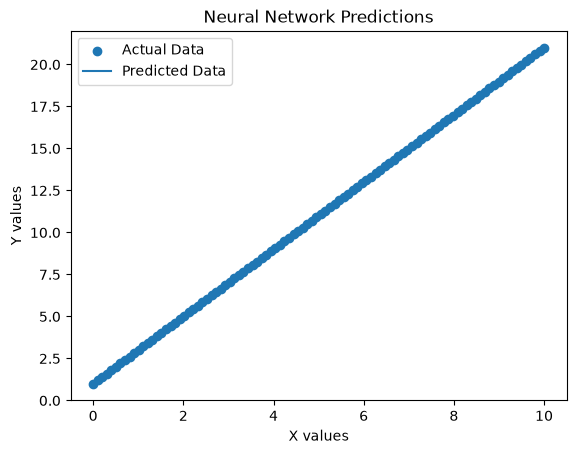

Learned weight: 1.9999840259552002
Learned bias: 1.0001062154769897


In [8]:
# -------------------------------------------------
# Question 4: Visualise actual data and predictions
# -------------------------------------------------
with torch.no_grad():
    predicted_values = model(X)

plt.scatter(X.numpy(), Y.numpy(), label="Actual Data")
plt.plot(X.numpy(), predicted_values.numpy(), label="Predicted Data")
plt.xlabel("X values")
plt.ylabel("Y values")
plt.title("Neural Network Predictions")
plt.legend()
plt.show()

# Inspect learned parameters
print("Learned weight:", model.layer.weight.item())
print("Learned bias:", model.layer.bias.item())

### Lab 15 assessment answers

    1. Neural network: A machine-learning model made of interconnected neurons/layers that learns patterns from data.
    2. PyTorch: A Python deep-learning library for tensors, automatic differentiation, and neural networks.
    3. Autograd: PyTorch’s automatic differentiation engine that computes gradients.
    4. Tensor: A multidimensional numerical array used by PyTorch; similar to a NumPy array but supports GPU and autograd.
    5. Loss function: Measures how far predictions are from actual values; training minimises it.
    6. Gradient descent: An optimisation method that updates parameters in the direction that reduces loss.
    7. backward(): Computes gradients of a scalar loss with respect to tensors that require gradients.
    8. Optimizer: Updates model parameters using computed gradients, e.g., SGD or Adam.
    9. Training vs testing data: Training data are used to learn parameters; testing data are used to evaluate generalisation.
    10. Three applications of neural networks: Image classification, speech recognition, price prediction, medical diagnosis, fraud detection.
